<a href="https://colab.research.google.com/github/smeason/pushT-project/blob/main/CS5180_PushT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install gym-pusht

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 MB 38.6 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 16.8 MB/s  0:00:00
  Attempting uninstall: opencv-python
    Found existing installation: opencv-python 5.0.0.93
    Uninstalling opencv-python-5.0.0.93:
      Successfully uninstalled opencv-python-5.0.0.93
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [gym-pusht]


In [ ]:
from matplotlib import animation
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
from pathlib import Path
import time

In [ ]:
# example.py
import gymnasium as gym
import gym_pusht

# env = gym.make("gym_pusht/PushT-v0",
#                render_mode='rgb_array',
#                obs_type="state")
# observation, info = env.reset()

# for _ in range(10):
#     action = env.action_space.sample()
#     observation, reward, terminated, truncated, info = env.step(action)
#     image = env.render()

#     if terminated or truncated:
#         observation, info = env.reset()

# env.close()

In [ ]:
from gymnasium import ActionWrapper, spaces

### Wrap pushT environment to use a velocity-based action space (instead of position)
class PushTVelocityWrapper(ActionWrapper):
    def __init__(self, env, max_speed=40.0):
        super().__init__(env)

        self.max_speed = max_speed
        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=env.action_space.shape,
            dtype=np.float32,
        )

    def action(self, normalized_velocity):
        current_position = np.asarray(self.unwrapped.agent.position, dtype=np.float32)

        velocity = np.clip(normalized_velocity, -1.0, 1.0) * self.max_speed
        target_position = current_position + velocity / self.unwrapped.control_hz

        low = self.env.action_space.low
        high = self.env.action_space.high
        return np.clip(target_position, low, high).astype(np.float32)

In [ ]:
import gymnasium as gym
import gym_pusht
import numpy as np


class DistanceCurriculum(gym.Wrapper):
    def __init__(
        self,
        env,
        max_distance=30,
        max_angle=np.deg2rad(15),
        max_attempts=20_000,
    ):
        super().__init__(env)
        self.max_attempts = max_attempts
        self.set_limits(max_distance, max_angle)

    def set_limits(self, max_distance, max_angle):
        """Distance is in environment units; angle is in radians."""
        if max_distance < 0:
            raise ValueError("max_distance must be nonnegative")
        if not 0 <= max_angle <= np.pi:
            raise ValueError("max_angle must be between 0 and pi")

        self.max_distance = max_distance
        self.max_angle = max_angle

    def reset(self, *, seed=None, options=None):
        for attempt in range(self.max_attempts):
            obs, info = self.env.reset(
                seed=seed if attempt == 0 else None,
                options=options,
            )

            base = self.env.unwrapped

            block_xy = np.asarray(base.block.position)
            goal_xy = np.asarray(base.goal_pose[:2])
            distance = np.linalg.norm(block_xy - goal_xy)

            block_angle = base.block.angle
            goal_angle = base.goal_pose[2]
            delta = block_angle - goal_angle
            angle_error = abs(np.arctan2(np.sin(delta), np.cos(delta)))

            if distance <= self.max_distance and angle_error <= self.max_angle:
                info = dict(info)
                info["initial_goal_distance"] = float(distance)
                info["initial_angle_error"] = float(angle_error)
                # print(f'attempt num: {attempt}')
                return obs, info

        raise RuntimeError(
            "Could not sample a reset satisfying both limits. "
            "Try relaxing them or increasing max_attempts."
        )


In [ ]:
"""Parameters"""
policy_type: str = "mlp"
state_dim: int = 5
action_dim: int = 2
lr_actor: float = 0.001
lr_critic: float = 0.001
max_ppo_steps: int = 10
max_episode_len: int = 300
clip: float = 0.2
discount_gamma: float = 0.99
gae_lambda: float = 0.90
update_epochs: int = 5
batch_size: int = 20
entropy_coefficient: float = 0.01

initial_max_dist: float = 30
initial_max_angle = 25 # degrees
max_speed = 70 # maximum speed of pusher arm

In [ ]:
env = DistanceCurriculum(
    gym.make("gym_pusht/PushT-v0",
             render_mode="rgb_array",
             obs_type="state"),
    max_distance=initial_max_dist,
    max_angle=np.deg2rad(initial_max_angle),
)

env = PushTVelocityWrapper(env, max_speed=max_speed)

print(f'{env.observation_space} | shape: {env.observation_space.shape[0]}')
print(f'{env.action_space} | shape: {env.action_space.shape[0]}')

obs, info = env.reset()
print("Distance:", info["initial_goal_distance"])
print("Angle error (degrees):", np.rad2deg(info["initial_angle_error"]))

# Increase difficulty between episodes:
# env.set_limits(max_distance=60, max_angle=np.deg2rad(30))

Box(0.0, [512.         512.         512.         512.           6.28318531], (5,), float64) | shape: 5
Box(-1.0, 1.0, (2,), float32) | shape: 2
Distance: 20.221793440862296
Angle error (degrees): 13.941151399035109


In [ ]:
# @title
############# print all hyperparameters #############

print("--------------------------------------------------------------------------------------------")

print("max training timesteps : ", max_ppo_steps)
print("max timesteps per episode : ", max_episode_len)

# print("model saving frequency : " + str(save_model_freq) + " timesteps")
# print("log frequency : " + str(log_freq) + " timesteps")
# print("printing average reward over episodes in last : " + str(print_freq) + " timesteps")

print("--------------------------------------------------------------------------------------------")

print("state space dimension : ", state_dim)
print("action space dimension : ", action_dim)

print("--------------------------------------------------------------------------------------------")

print("Initializing a continuous action space policy")
print("--------------------------------------------------------------------------------------------")
# print("starting std of action distribution : ", action_std)
# print("decay rate of std of action distribution : ", action_std_decay_rate)
# print("minimum std of action distribution : ", min_action_std)
# print("decay frequency of std of action distribution : " + str(action_std_decay_freq) + " timesteps")

print("--------------------------------------------------------------------------------------------")

# print("PPO update frequency : " + str() + " timesteps")
print("PPO K epochs : ", update_epochs)
print("PPO epsilon clip : ", clip)
print("discount factor (gamma) : ", discount_gamma)

print("--------------------------------------------------------------------------------------------")

print("optimizer learning rate actor : ", lr_actor)
print("optimizer learning rate critic : ", lr_critic)

--------------------------------------------------------------------------------------------
max training timesteps :  100
max timesteps per episode :  200
--------------------------------------------------------------------------------------------
state space dimension :  5
action space dimension :  2
--------------------------------------------------------------------------------------------
Initializing a continuous action space policy
--------------------------------------------------------------------------------------------
--------------------------------------------------------------------------------------------
PPO K epochs :  10
PPO epsilon clip :  0.2
discount factor (gamma) :  0.99
--------------------------------------------------------------------------------------------
optimizer learning rate actor :  0.0003
optimizer learning rate critic :  0.0003


In [ ]:
import copy

import numpy as np
import torch
import torch.nn as nn
from torch.distributions import Normal


class RolloutBuffer:
    def __init__(self):
        self.actions = []
        self.states = []
        self.logprobs = []
        self.rewards = []
        self.state_values = []
        self.is_terminals = []

    def clear(self):
        self.actions.clear()
        self.states.clear()
        self.logprobs.clear()
        self.rewards.clear()
        self.state_values.clear()
        self.is_terminals.clear()


class ActorCritic(nn.Module):
    def __init__(self, state_dim: int, action_dim: int, action_std: float = 0.5):
        super().__init__()
        self.actor = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, action_dim),
            nn.Tanh(),
        )
        self.critic = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 128),
            nn.Tanh(),
            nn.Linear(128, 64),
            nn.Tanh(),
            nn.Linear(64, 1),
        )
        self.log_std = nn.Parameter(torch.full((action_dim,), np.log(action_std)))

    def get_distribution(self, state: torch.Tensor) -> Normal:
        mean = self.actor(state)
        std = self.log_std.exp().expand_as(mean)
        return Normal(mean, std)

    def act(self, state: torch.Tensor):
        dist = self.get_distribution(state)
        action = dist.sample()
        return action, dist.log_prob(action).sum(dim=-1), self.critic(state).squeeze(-1)

    def evaluate(self, state: torch.Tensor, action: torch.Tensor):
        dist = self.get_distribution(state)
        log_prob = dist.log_prob(action).sum(dim=-1)
        entropy = dist.entropy().sum(dim=-1)
        value = self.critic(state).squeeze(-1)
        return log_prob, value, entropy


class PPO:
    def __init__(
        self,
        env,
        policy_type: str = "mlp",
        state_dim: int = 5,
        action_dim: int = 2,
        lr_actor: float = 0.0003,
        lr_critic: float = 0.0003,
        max_ppo_steps: int = 100,
        max_episode_len: int = 200,
        clip: float = 0.2,
        discount_gamma: float = 0.99,
        gae_lambda: float = 0.90,
        update_epochs: int = 10,
        batch_size: int = 20,
        entropy_coefficient: float = 0.01
    ) -> None:
        self.env = env
        self.policy_type = policy_type
        if policy_type != "mlp":
            raise NotImplementedError("Only the MLP policy is implemented")

        self.state_dim = state_dim if state_dim is not None else env.observation_space.shape[0]
        self.action_dim = action_dim if action_dim is not None else env.action_space.shape[0]
        self.max_steps = max_ppo_steps
        self.MAX_EPISODE_LEN = max_episode_len
        self.clip = clip
        self.discount_gamma = discount_gamma
        self.gae_lambda = gae_lambda
        self.update_epochs = update_epochs
        self.num_rollouts = batch_size
        self.entropy_coefficient = entropy_coefficient
        self.buffer = RolloutBuffer()

        self.policy = ActorCritic(self.state_dim, self.action_dim)
        self.policy_old = copy.deepcopy(self.policy)
        self.policy_old.eval()

        self.optimizer = torch.optim.Adam([
            {"params": self.policy.actor.parameters(), "lr": lr_actor},
            {"params": self.policy.critic.parameters(), "lr": lr_critic},
            {"params": self.policy.log_std, "lr": lr_actor},
        ])
        self.loss_fn = nn.MSELoss()

    def _to_environment_action(self, action: torch.Tensor) -> np.ndarray:
        # convert raw action tensor output to usable action numpy array
        action = action.detach().cpu().numpy()
        if action.ndim == 2:
            action = action[0]

        low = np.asarray(self.env.action_space.low, dtype=np.float32)
        high = np.asarray(self.env.action_space.high, dtype=np.float32)
        scaled = low + (high - low) * (np.clip(action, -1.0, 1.0) + 1.0) / 2.0
        return scaled.astype(np.float32)

    def collect_dataset(self):
        self.buffer.clear()
        self.policy_old.eval()

        start_pose = None
        end_pose = None
        trajectory = []
        total_rewards = []
        episode_lengths = []

        for i in range(self.num_rollouts):
            observation, _ = self.env.reset()
            if i == 0:
                start_pose = env.render()
                # start_pose = observation[2:]

            ep_reward = 0
            ep_len = 0

            for _ in range(self.MAX_EPISODE_LEN):
                state = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
                with torch.no_grad():
                    action, log_prob, state_value = self.policy_old.act(state)

                environment_action = self._to_environment_action(action)
                next_observation, reward, terminated, truncated, _ = self.env.step(environment_action)
                done = terminated or truncated

                self.buffer.states.append(state.squeeze(0))
                self.buffer.actions.append(action.squeeze(0))
                self.buffer.logprobs.append(log_prob.squeeze(0))
                self.buffer.rewards.append(float(reward))
                self.buffer.state_values.append(state_value.squeeze(0))
                self.buffer.is_terminals.append(done)

                if i == 0:
                    # trajectory.append(
                    #     np.array(self.env.unwrapped.agent.position, dtype=np.float64)
                    # )
                    trajectory.append(observation[0:2]) # add agent x,y position
                ep_reward += float(reward)
                ep_len += 1
                observation = next_observation

                if done:
                    break

            if i == 0:
                # end_pose = observation[2:]
                end_pose = env.render()

            total_rewards.append(ep_reward)
            episode_lengths.append(ep_len)

        return (self.buffer, np.mean(total_rewards), np.mean(episode_lengths),
            start_pose, end_pose, trajectory)

    def _capture_rgb_frame(self):
        frame = self.env.render()
        print(f'frame type: {type(frame)}')
        frame = np.asarray(frame)
        if frame.ndim != 3 or frame.shape[2] < 3:
            raise ValueError(f"Expected an RGB image, got shape {frame.shape}")
        return frame[:, :, :3].copy()

    def update_policy_clip(self):

        states = torch.stack(self.buffer.states).detach()
        actions = torch.stack(self.buffer.actions).detach()
        old_logprobs = torch.stack(self.buffer.logprobs).detach()
        values = torch.stack(self.buffer.state_values).detach().float()
        rewards = torch.tensor(self.buffer.rewards, dtype=torch.float32)
        dones = torch.tensor(self.buffer.is_terminals, dtype=torch.float32)

        # calculate rewards to go
        returns = []
        G = 0.0
        for reward, done in zip(reversed(rewards.tolist()), reversed(dones.tolist())):
            if done:
                G = 0.0
            G = reward + self.discount_gamma * G
            returns.append(G)
        returns = torch.tensor(list(reversed(returns)), dtype=torch.float32)

        # calculate gae - generalized advantage estimate
        advantages = torch.zeros_like(returns)
        gae = 0.0
        next_value = 0.0
        for t in reversed(range(len(rewards))):
            if t == len(rewards) - 1 or dones[t] > 0:
                next_value = 0.0
            else:
                next_value = values[t + 1]

            delta = rewards[t] + self.discount_gamma * next_value - values[t]
            gae = delta + self.discount_gamma * self.gae_lambda * gae * (1.0 - dones[t])
            advantages[t] = gae

        advantages = (advantages - advantages.mean()) / (advantages.std(unbiased=False) + 1e-8)

        # update policy with gradient ascent
        for _ in range(self.update_epochs):
            logprobs, state_values, entropy = self.policy.evaluate(states, actions)
            ratios = torch.exp(logprobs - old_logprobs)
            surrogate_one = ratios * advantages
            surrogate_two = torch.clamp(
                ratios, 1.0 - self.clip, 1.0 + self.clip
            ) * advantages

            policy_loss = -torch.min(surrogate_one, surrogate_two).mean()
            value_loss = self.loss_fn(state_values, returns)
            entropy_loss = -self.entropy_coefficient * entropy.mean()
            loss = policy_loss + 0.5 * value_loss + entropy_loss

            self.optimizer.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(self.policy.parameters(), 0.5)
            self.optimizer.step()

        self.policy_old.load_state_dict(self.policy.state_dict())
        self.buffer.clear()

    def run(self):
        for i in range(self.max_steps):
            start_time = time.perf_counter()
            _, avg_reward, avg_ep_len, start_pose, end_pose, trajectory = self.collect_dataset()
            end_time = time.perf_counter()
            print(f'Step {i:03d}/{self.max_steps} | Avg Reward: {avg_reward:.4f} | Avg Episode Length: {avg_ep_len:.1f} | collect time: {(end_time - start_time):.2f} s')
            # print(f'start pose: {start_pose} | end_pose: {end_pose} | trajectory: {trajectory}')
            # print(f'start pose type: {type(start_pose[0])} | trajectory type: {type(trajectory[0])} {type(trajectory[0][0])}')
            # observations are numpy float64
            self.save_rollout_as_jpg(start_pose, end_pose, trajectory, i)
            start_time = time.perf_counter()
            self.update_policy_clip()
            end_time = time.perf_counter()
            print(f'update policy in {(end_time - start_time):.2f} s')

    def act(self, state):
        state = torch.as_tensor(state, dtype=torch.float32).unsqueeze(0)
        with torch.no_grad():
            action, log_prob, state_value = self.policy_old.act(state)
        return action, log_prob, state_value

    def save_rollout_as_jpg(self, start_pose, end_pose, trajectory, step):
        overlay = np.clip(0.5*start_pose + 0.5 * end_pose, 0, 255).astype(np.uint8)
        trajectory = np.asarray(trajectory, dtype=np.float64)
        # print(f'trajectory shape: {trajectory.shape}')

        fig, ax = plt.subplots(figsize=(7,7))
        ax.imshow(overlay, extent=(0, 512, 512, 0))

        ax.plot(trajectory[:,0], trajectory[:,1], color="blue", linewidth=2, label="Agent path")
        ax.scatter(*trajectory[0], color="yellow", s=30, label="Agent start")
        ax.scatter(*trajectory[-1], color="red", s=30, label="Agent end")

        ax.set_xlim(0, 512)
        ax.set_ylim(0, 512)
        ax.set_aspect('equal')
        ax.set_title(f'Rollout {step}')

        fig.tight_layout()
        fig.savefig(f"rollout_{step:03d}.jpg")
        plt.close(fig)

    def save(self, checkpoint_path):
        torch.save(self.policy_old.state_dict(), checkpoint_path)

In [ ]:
model = PPO(env,
            policy_type='mlp',
            state_dim=state_dim,
            action_dim=action_dim,
            lr_actor=lr_actor,
            lr_critic=lr_critic,
            max_ppo_steps=max_ppo_steps,
            max_episode_len=max_episode_len,
            clip=clip,
            discount_gamma=discount_gamma,
            gae_lambda=gae_lambda,
            update_epochs=update_epochs,
            batch_size=batch_size,
            entropy_coefficient=entropy_coefficient
        )

In [ ]:
model.run()

Step 000/10 | Avg Reward: 158.1540 | Avg Episode Length: 300.0 | collect time: 19.06 s
update policy in 0.87 s
Step 001/10 | Avg Reward: 141.1300 | Avg Episode Length: 300.0 | collect time: 18.14 s
update policy in 1.08 s
Step 002/10 | Avg Reward: 159.1142 | Avg Episode Length: 300.0 | collect time: 17.21 s
update policy in 1.13 s
Step 003/10 | Avg Reward: 158.6107 | Avg Episode Length: 300.0 | collect time: 16.33 s
update policy in 0.86 s
Step 004/10 | Avg Reward: 150.1054 | Avg Episode Length: 300.0 | collect time: 18.18 s
update policy in 0.87 s
Step 005/10 | Avg Reward: 139.1193 | Avg Episode Length: 300.0 | collect time: 15.16 s
update policy in 0.77 s
Step 006/10 | Avg Reward: 150.6832 | Avg Episode Length: 300.0 | collect time: 14.68 s
update policy in 0.77 s
Step 007/10 | Avg Reward: 150.5986 | Avg Episode Length: 300.0 | collect time: 15.79 s
update policy in 0.76 s
Step 008/10 | Avg Reward: 152.6000 | Avg Episode Length: 300.0 | collect time: 14.36 s
update policy in 0.80 s
S

In [ ]:
def save_frames_as_gif(frames, path):
    plt.figure(figsize=(frames[0].shape[1] / 72.0, frames[0].shape[1] / 72.0), dpi=72)
    patch = plt.imshow(frames[0])
    plt.axis('off')

    def animate(i):
        patch.set_data(frames[i])

    anim = animation.FuncAnimation(
        plt.gcf(), animate, frames=len(frames), interval=50
    )
    anim.save(path, writer="pillow", fps=60)

    plt.close()

## TODO: Need to enforce direction consistency and/or pick action every x timesteps

action: [-0.05683351  0.3531506 ]
action: [ 0.39180005 -0.11686039]
action: [-0.70761347  0.71161413]
action: [-0.52447426  0.15437758]
action: [0.02709675 0.7596538 ]
action: [-0.11114454  0.02298045]
action: [-0.07939744  0.37422085]
action: [0.5652381 0.6530874]
action: [-0.3950957  -0.07724661]
action: [0.21352434 0.71309173]
action: [0.4618827 0.5059531]
action: [0.17691195 0.24453032]
action: [-0.6778077   0.07420588]
action: [0.36830592 0.3694998 ]
action: [0.6080867  0.10539198]
action: [-0.3667161  0.3180995]
action: [0.75979495 0.8732598 ]
action: [0.5620153  0.71177316]
action: [ 0.13918972 -0.9986141 ]
action: [ 0.7479733  -0.12550354]
action: [0.9062991  0.24208188]
action: [ 0.61611974 -0.00209904]
action: [0.25493085 0.4397875 ]
action: [0.27319813 0.39107716]
action: [-0.06209207 -1.        ]
action: [ 0.7221961  -0.07142824]
action: [-0.40518576  0.07054579]
action: [ 0.96246386 -0.84223676]
action: [0.6484338 0.1182847]
action: [0.05973864 0.37838507]
action: [ 1.    

KeyboardInterrupt: 

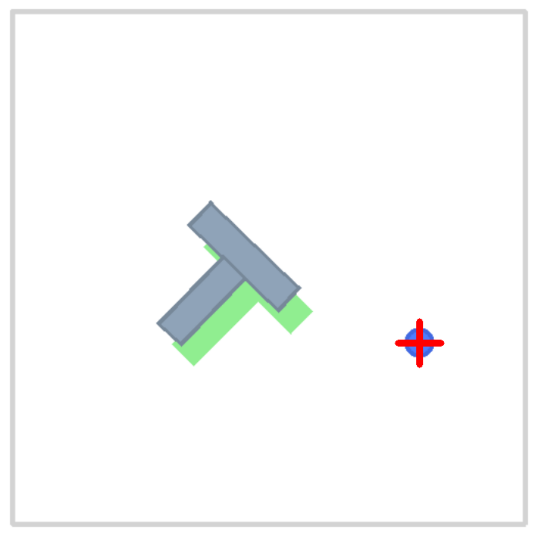

In [ ]:
### Test policy and save results as gifs

# asdf = model.save('checkpoint.pt')

# record 10 random rollouts
NUM_TEST_ROLLOUTS = 5
for i in range(NUM_TEST_ROLLOUTS):

    observation, info = env.reset()
    frames = []
    for _ in range(300):
        state = torch.as_tensor(observation, dtype=torch.float32).unsqueeze(0)
        # action = model.policy.act(state)
        with torch.no_grad():
            action, _, _ = model.policy_old.act(state)
            environment_action = model._to_environment_action(action)

        # FIX: Pass environment_action (numpy array) instead of the raw PyTorch tensor action
        print(f"action: {environment_action}")
        observation, reward, terminated, truncated, info = env.step(environment_action)
        frames.append(env.render())

        if terminated or truncated:
            # observation, info = env.reset()
            break

    # FIX: Pass a saving path to the gif function
    save_frames_as_gif(frames, f'rollout_{i}.gif')